## INF201 - Deliverable 1

### Group info:

ID: `G5_4`

Members:
* Stig Espen Paulsberg
* Vinicius Millan Santa Catharina
* Zaur Kambiev 

### Task 1

### Task 2

In [ ]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters_precip = {
 'sources': 'SN17850',
 'elements': 'sum(precipitation_amount P1D)',
 'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters_precip, auth=(client_id,''))
# Extract JSON data
json = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data_precip = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])


Data retrieved from frost.met.no!


In [ ]:
# This will return a Dataframe with all of the observations in a table format
# Intructions: https://frost.met.no/python_example.html

rows_precip = []

for i in range(len(data_precip)):
    row = pd.DataFrame(data_precip[i]['observations'])
    row['referenceTime'] = data_precip[i]['referenceTime']
    row['sourceId'] = data_precip[i]['sourceId']
    rows_precip.append(row)

df_precip = pd.concat(rows_precip, ignore_index=True)

df_precip['referenceTime'] = pd.to_datetime(df_precip['referenceTime'])

df_precip.head()

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,referenceTime,sourceId
0,sum(precipitation_amount P1D),5.4,mm,PT18H,P1D,0,C,2,NaN,2025-01-01 00:00:00+00:00,SN17850:0
1,sum(precipitation_amount P1D),6.6,mm,PT6H,P1D,0,C,2,0.0,2025-01-01 00:00:00+00:00,SN17850:0
2,sum(precipitation_amount P1D),0.0,mm,PT18H,P1D,0,C,2,NaN,2025-01-02 00:00:00+00:00,SN17850:0
3,sum(precipitation_amount P1D),1.9,mm,PT6H,P1D,0,C,2,0.0,2025-01-02 00:00:00+00:00,SN17850:0
4,sum(precipitation_amount P1D),0.1,mm,PT18H,P1D,0,C,2,NaN,2025-01-03 00:00:00+00:00,SN17850:0


In [ ]:
# Create a df with the precipiation measuremente of the PT6H timeOffset

df_precip_6H = df_precip[df_precip['timeOffset'] == "PT6H"]
df_precip_6H.head()

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,referenceTime,sourceId
1,sum(precipitation_amount P1D),6.6,mm,PT6H,P1D,0,C,2,0.0,2025-01-01 00:00:00+00:00,SN17850:0
3,sum(precipitation_amount P1D),1.9,mm,PT6H,P1D,0,C,2,0.0,2025-01-02 00:00:00+00:00,SN17850:0
5,sum(precipitation_amount P1D),0.1,mm,PT6H,P1D,0,C,2,0.0,2025-01-03 00:00:00+00:00,SN17850:0
7,sum(precipitation_amount P1D),0.0,mm,PT6H,P1D,0,C,2,0.0,2025-01-04 00:00:00+00:00,SN17850:0
9,sum(precipitation_amount P1D),0.0,mm,PT6H,P1D,0,C,2,0.0,2025-01-05 00:00:00+00:00,SN17850:0


In [ ]:
# Create a list with the total precipitation of each month for the PT6H timeOffset
monthly_total = []

for i in range(1,13):
    total = df_precip_6H[df_precip_6H['referenceTime'].dt.month==i]['value'].sum()
    monthly_total.append(total)

monthly_total

[np.float64(86.4),
 np.float64(38.800000000000004),
 np.float64(15.7),
 np.float64(21.6),
 np.float64(35.400000000000006),
 np.float64(93.3),
 np.float64(77.00000000000001),
 np.float64(110.30000000000001),
 np.float64(145.6),
 np.float64(124.89999999999999),
 np.float64(84.89999999999998),
 np.float64(116.3)]

In [ ]:
# one date for each month (15)
months_dates = []

for i in range(1,13):
    date = "2025-"+str(i)+"-15"
    months_dates.append(date)

months_dates = pd.to_datetime(months_dates)


DatetimeIndex(['2025-01-15', '2025-02-15', '2025-03-15', '2025-04-15',
               '2025-05-15', '2025-06-15', '2025-07-15', '2025-08-15',
               '2025-09-15', '2025-10-15', '2025-11-15', '2025-12-15'],
              dtype='datetime64[us]', freq=None)


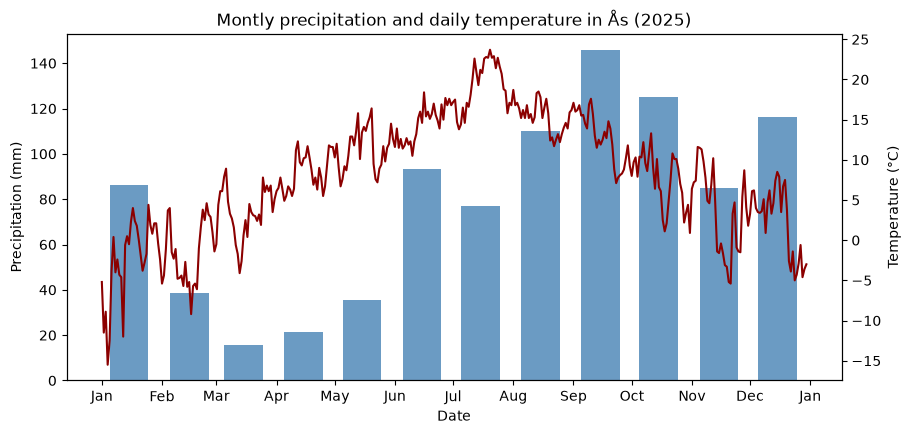

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax2 = ax1.twinx()

ax1.bar(
    months_dates,        
    monthly_total,
    width=20,
    alpha=0.8,
    color='steelblue'
)
ax1.set_ylabel("Precipitation (mm)")
ax1.set_xlabel("Date")
ax1.set_title("Montly precipitation and daily temperature in Ås (2025)")
ax2.plot(
    df_temp['referenceTime'],
    df_temp['value'],
    color='darkred'
)
ax2.xaxis.set_major_locator(mdates.MonthLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax2.set_ylabel("Temperature (°C)")

plt.show()

### Task 3

### Task 4

### Task 5